In [31]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from opencv_tools import opencv_tools

In [32]:
img = cv2.imread('../dataset/img/lenna.jpg')

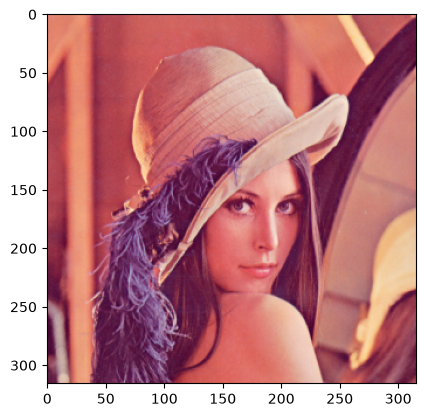

In [33]:
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

In [34]:
rng = np.random.default_rng(42)

### Add Gaussian Noise

In [35]:
def add_gaussian_noise(img, level):
    img = img.astype(np.float32)
    sigma = 255 * level
    noise = rng.normal(loc=0, scale=sigma, size=img.shape)
    noisy = img + noise
    return np.clip(a=noisy, a_min=0, a_max=255).astype(np.uint8)

In [36]:
guassian_images = [add_gaussian_noise(img, 0.1), add_gaussian_noise(img, 0.2), add_gaussian_noise(img, 0.3)]

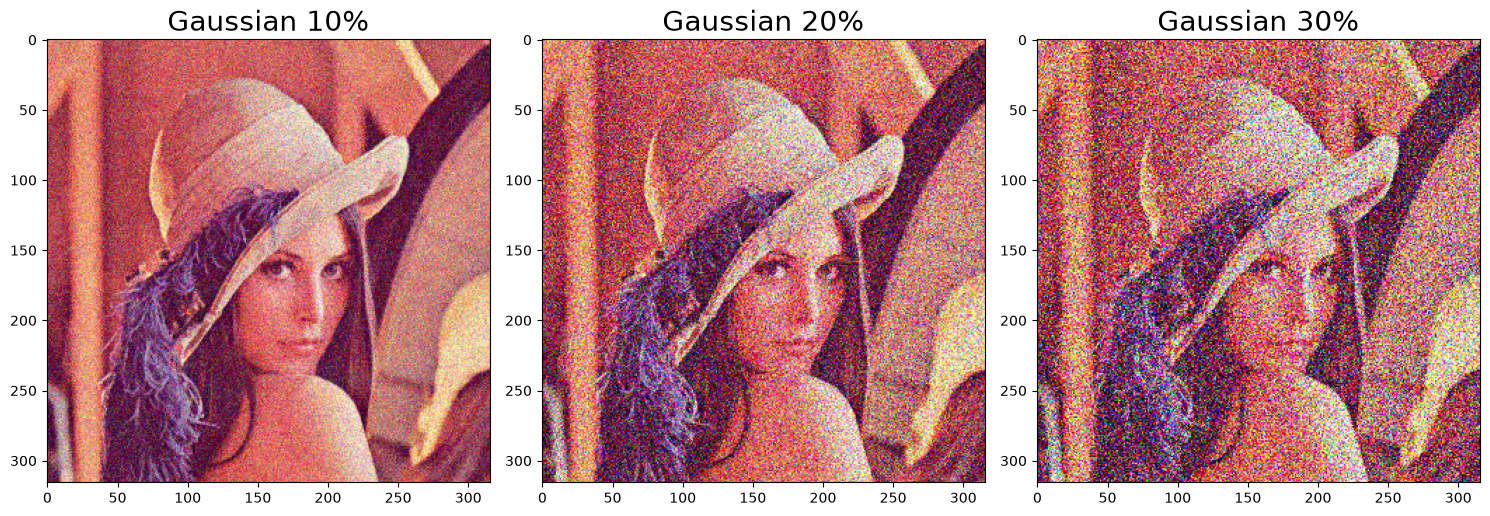

In [37]:
opencv_tools.show_img_by_matplotlib_1x3(
    "Gaussian 10%", guassian_images[0],
    "Gaussian 20%", guassian_images[1],
    "Gaussian 30%", guassian_images[2]
    )

In [45]:
gaussian_blurs = [cv2.GaussianBlur(src=guassian_images[0], ksize=(3, 3), sigmaX=0), cv2.GaussianBlur(src=guassian_images[1], ksize=(5, 5), sigmaX=0), cv2.GaussianBlur(src=guassian_images[2], ksize=(7, 7), sigmaX=0)]

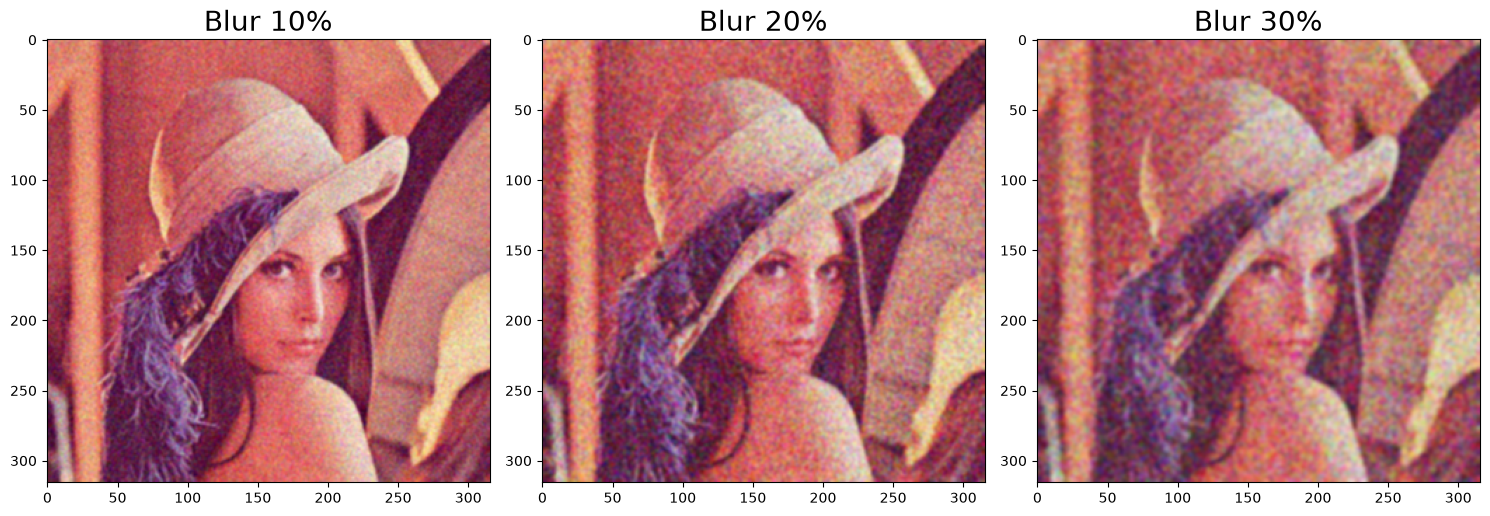

In [46]:
opencv_tools.show_img_by_matplotlib_1x3(
    "Blur 10%", gaussian_blurs[0],
    "Blur 20%", gaussian_blurs[1],
    "Blur 30%", gaussian_blurs[2]
    )

In [51]:
sharpen_kernels = {
    "10%": np.array([
        [-0.5, -0.5, -0.5],
        [-0.5,  5.0, -0.5],
        [-0.5, -0.5, -0.5]
    ], dtype=np.float32),

    "20%": np.array([
        [-0.25, -0.25, -0.25],
        [-0.25,  3.0,  -0.25],
        [-0.25, -0.25, -0.25]
    ], dtype=np.float32),

    "30%": np.array([
        [0, 0, 0],
        [0, 1, 0],
        [0, 0, 0]
    ], dtype=np.float32)
}

In [52]:
sharp_images = [cv2.filter2D(gaussian_blurs[0], -1, sharpen_kernels["10%"]), cv2.filter2D(gaussian_blurs[1], -1, sharpen_kernels["20%"]), cv2.filter2D(gaussian_blurs[2], -1, sharpen_kernels["30%"])]

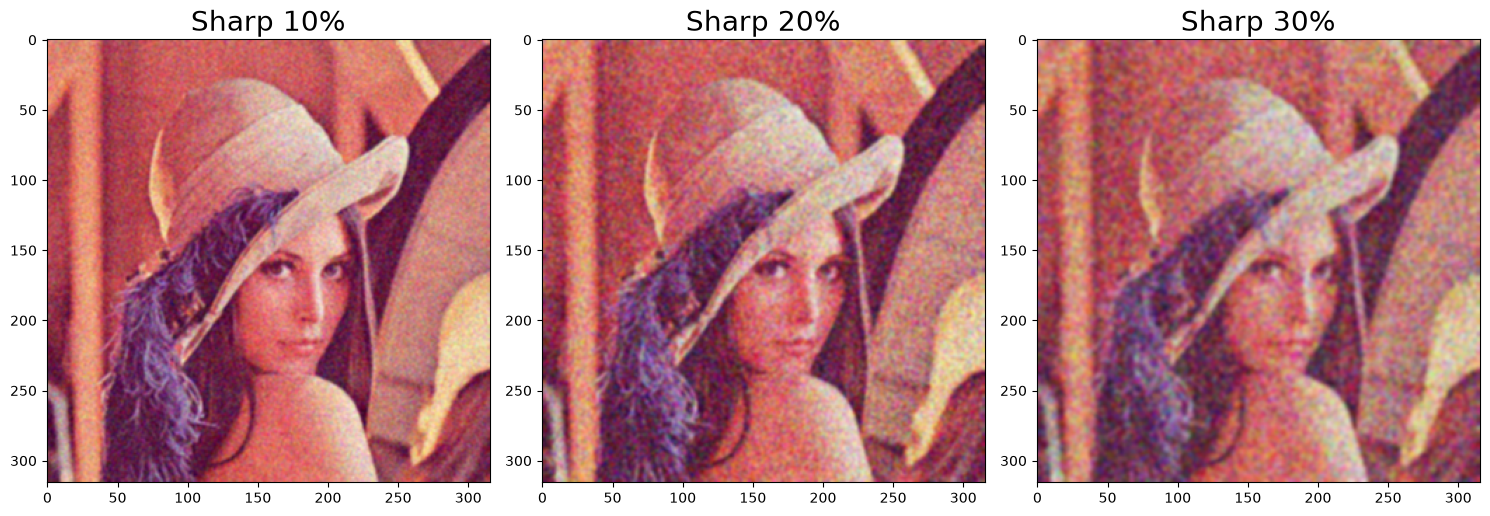

In [53]:
opencv_tools.show_img_by_matplotlib_1x3(
    "Sharp 10%", gaussian_blurs[0],
    "Sharp 20%", gaussian_blurs[1],
    "Sharp 30%", gaussian_blurs[2]
    )